In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report

In [11]:
# Load dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.xls")

In [12]:
# Dataset information
print("\nDataset info:")
df.info()

print("\nDataset shape:")
print(df.shape)

print("\nColumns:")
print(df.columns)
 


Dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str 

In [13]:
# First few rows
print("\nFirst few rows:")
pd.set_option("display.max_columns", None)
display(df.head(10))


First few rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,Yes,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [14]:
# Basic statistics
print("\n" + "="*50)
print("BASIC STATISTICS")
print("="*50)
print(df.describe())

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Check for missing values
print("\n" + "="*50)
print("MISSING VALUES")
print("="*50)
missing = df.isnull().sum()
if missing.sum() == 0:
    print("✓ No missing values found!")
else:
    print(missing[missing > 0])


# Target distribution
print("\n" + "="*50)
print("CHURN DISTRIBUTION")
print("="*50)
print(df["Churn"].value_counts())


BASIC STATISTICS
       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.761692
std         0.368612    24.559481       30.090047
min         0.000000     0.000000       18.250000
25%         0.000000     9.000000       35.500000
50%         0.000000    29.000000       70.350000
75%         0.000000    55.000000       89.850000
max         1.000000    72.000000      118.750000

MISSING VALUES
TotalCharges    11
dtype: int64

CHURN DISTRIBUTION
Churn
No     5174
Yes    1869
Name: count, dtype: int64


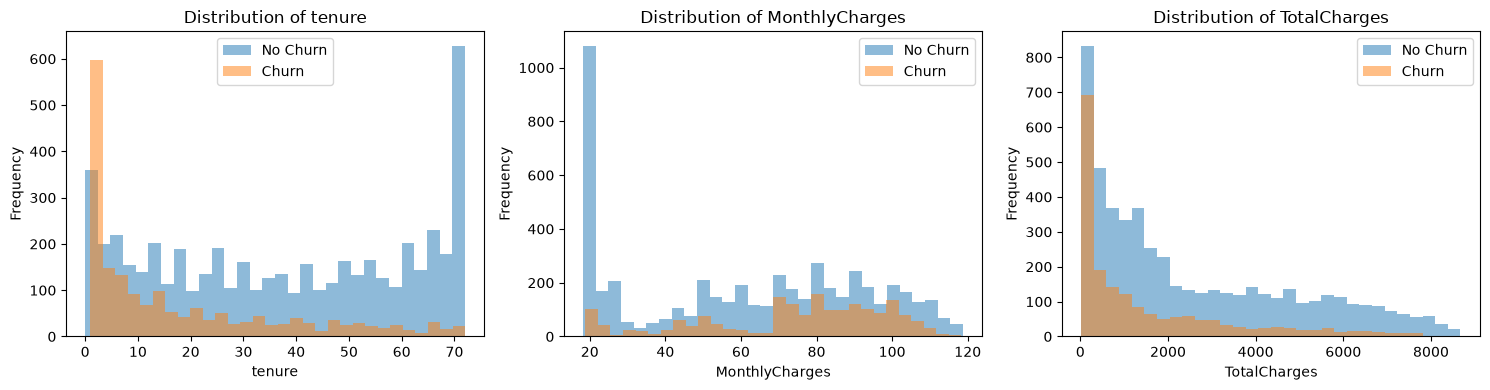

In [15]:
# Visualize key features
key_features = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for idx, feature in enumerate(key_features):
    axes[idx].hist(df[df["Churn"] == "No"][feature], alpha=0.5, label="No Churn", bins=30)
    axes[idx].hist(df[df["Churn"] == "Yes"][feature], alpha=0.5, label="Churn", bins=30)
    axes[idx].set_xlabel(feature)
    axes[idx].set_ylabel("Frequency")
    axes[idx].set_title(f"Distribution of {feature}")
    axes[idx].legend()

plt.tight_layout()
plt.show()

In [16]:
# Handle missing values
df = df.dropna()

# Convert target to binary
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

# Separate features and target
X = df.drop(["Churn", "customerID"], axis=1)
y = df["Churn"]

# Convert categorical variables to numeric
X = pd.get_dummies(X, drop_first=True, dtype=int)


print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (7032, 30)
Target shape: (7032,)


In [20]:
# Split into training and testing sets
# random_state ensures reproducibility
# stratify=y ensures both sets have similar class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

print("\n" + "="*50)
print("DATA SPLIT")
print("="*50)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")
print(f"Training features: {X_train.shape[1]}")
print(f"Test features: {X_test.shape[1]}")

print("\nTraining set target distribution:")
print(y_train.value_counts())
print(f"  No Churn (0): {(y_train == 0).sum()} ({(y_train == 0).mean()*100:.1f}%)")
print(f"  Churn (1): {(y_train == 1).sum()} ({(y_train == 1).mean()*100:.1f}%)")

print("\nTest set target distribution:")
print(y_test.value_counts())
print(f"  No Churn (0): {(y_test == 0).sum()} ({(y_test == 0).mean()*100:.1f}%)")
print(f"  Churn (1): {(y_test == 1).sum()} ({(y_test == 1).mean()*100:.1f}%)")


DATA SPLIT
Training set size: 5625 samples
Test set size: 1407 samples
Training features: 30
Test features: 30

Training set target distribution:
Churn
0    4130
1    1495
Name: count, dtype: int64
  No Churn (0): 4130 (73.4%)
  Churn (1): 1495 (26.6%)

Test set target distribution:
Churn
0    1033
1     374
Name: count, dtype: int64
  No Churn (0): 1033 (73.4%)
  Churn (1): 374 (26.6%)


In [22]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train_scaled, y_train)

print("KNN classifier trained successfully!")
print(f"Number of neighbors (k): {knn.n_neighbors}")

KNN classifier trained successfully!
Number of neighbors (k): 5


In [23]:
y_train_pred = knn.predict(X_train_scaled)
y_test_pred = knn.predict(X_test_scaled)

print(f"\nTraining predictions: {len(y_train_pred)}")
print(f"Test predictions: {len(y_test_pred)}")


Training predictions: 5625
Test predictions: 1407


In [25]:
# Calculate metrics
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_confusion = confusion_matrix(y_test, y_test_pred)

print("=== Model Performance ===")
print(f"\nTraining Accuracy: {train_accuracy:.4f} ({train_accuracy*100:.2f}%)")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")

print(f"\nTest Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")


print("\n=== Confusion Matrix ===")
print("                Predicted")
print("             No Churn   Churn")
print(f"Actual No Churn   {test_confusion[0,0]:4d}      {test_confusion[0,1]:4d}")
print(f"Actual Churn      {test_confusion[1,0]:4d}      {test_confusion[1,1]:4d}")


print("\n=== Classification Report ===")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["No Churn", "Churn"]
))

=== Model Performance ===

Training Accuracy: 0.8348 (83.48%)
Test Accuracy: 0.7534 (75.34%)

Test Precision: 0.5362
Test Recall: 0.5348

=== Confusion Matrix ===
                Predicted
             No Churn   Churn
Actual No Churn    860       173
Actual Churn       174       200

=== Classification Report ===
              precision    recall  f1-score   support

    No Churn       0.83      0.83      0.83      1033
       Churn       0.54      0.53      0.54       374

    accuracy                           0.75      1407
   macro avg       0.68      0.68      0.68      1407
weighted avg       0.75      0.75      0.75      1407



The difference of around 8% between Training Accuracy and Test Accurary could be an indicator for slight overfitting.
The model has rather low precision and recall scores.

A possible solution could be to change k for less overfitting.


EXPERIMENTING WITH DIFFERENT K VALUES
K= 1: Accuracy=0.7249, Precision=0.4835, Recall=0.5107
K= 3: Accuracy=0.7441, Precision=0.5178, Recall=0.5455
K= 5: Accuracy=0.7534, Precision=0.5362, Recall=0.5348
K= 7: Accuracy=0.7491, Precision=0.5279, Recall=0.5321
K= 9: Accuracy=0.7662, Precision=0.5610, Recall=0.5535
K=11: Accuracy=0.7697, Precision=0.5694, Recall=0.5481
K=15: Accuracy=0.7711, Precision=0.5734, Recall=0.5428

Results:
    K  Accuracy  Precision    Recall
0   1  0.724947   0.483544  0.510695
1   3  0.744136   0.517766  0.545455
2   5  0.753376   0.536193  0.534759
3   7  0.749112   0.527851  0.532086
4   9  0.766169   0.560976  0.553476
5  11  0.769723   0.569444  0.548128
6  15  0.771144   0.573446  0.542781


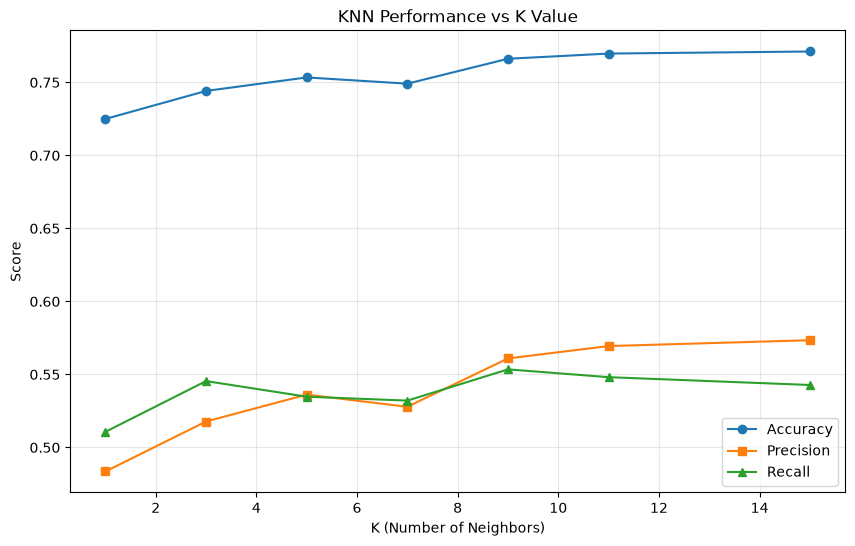

In [26]:
print("\n" + "="*50)
print("EXPERIMENTING WITH DIFFERENT K VALUES")
print("="*50)

k_values = [1, 3, 5, 7, 9, 11, 15]
results = []

for k in k_values:

    # Create and train model
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train_scaled, y_train)

    # Make predictions
    y_pred_temp = knn_temp.predict(X_test_scaled)

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred_temp)
    prec = precision_score(y_test, y_pred_temp)
    rec = recall_score(y_test, y_pred_temp)

    results.append({
        'K': k,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec
    })

    print(f"K={k:2d}: Accuracy={acc:.4f}, Precision={prec:.4f}, Recall={rec:.4f}")


# Convert results to DataFrame
results_df = pd.DataFrame(results)

print("\nResults:")
print(results_df)


# Visualize results
plt.figure(figsize=(10, 6))

plt.plot(results_df['K'], results_df['Accuracy'], marker='o', label='Accuracy')
plt.plot(results_df['K'], results_df['Precision'], marker='s', label='Precision')
plt.plot(results_df['K'], results_df['Recall'], marker='^', label='Recall')

plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Score')
plt.title('KNN Performance vs K Value')
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

Bigger k values seem to reach a higher accuracy. A k value of 9 shows the best improvement while still not being too big.

In [28]:
print(f"Selected K: 9")
print(f"Test Accuracy: {0.7662*100:.2f}%")

print(df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].mean())

Selected K: 9
Test Accuracy: 76.62%
          tenure  MonthlyCharges  TotalCharges
Churn                                         
0      37.650010       61.307408   2555.344141
1      17.979133       74.441332   1531.796094


The model has an accuracy of around 77%. However, one limitation is that according to the recall value, only around 55% of the actual churn cases are detected.

A recommendation for the client would be to focus on customers with a high predicted churn risk.

Customers who churn tend to have a lower tenure and higher monthly charges than customers who do not churn.

In [29]:
knn_best = KNeighborsClassifier(n_neighbors=9)
knn_best.fit(X_train_scaled, y_train)

churn_probability = knn_best.predict_proba(X_test_scaled)[:, 1]

risk_customers = df.loc[X_test.index, ["customerID"]].copy()

risk_customers["Churn_Probability"] = churn_probability

risk_customers.sort_values(
    "Churn_Probability",
    ascending=False
).head(10)

,customerID,Churn_Probability
2927,5542-TBBWB,1.000000
1334,1768-ZAIFU,1.000000
2156,2737-YNGYW,1.000000
3682,3716-BDVDB,1.000000
809,1820-TQVEV,1.000000
3727,9057-SIHCH,1.000000
1739,9804-ICWBG,1.000000
1526,2984-AFWNC,1.000000
4484,7465-ZZRVX,1.000000
702,1766-GKNMI,0.888889
